# Система прогнозирования продаж для «Прилавка»

<h1>Ml модель прогноза продаж</h1>

<h3>Цель:</h3>
<p>
Разработать автоматизированную систему прогнозирования недельных продаж для каждого отдела во всех дарксторах с использованием машинного обучения (модель CatBoost). Система будет работать в режиме пакетного внедрения с недельным циклом: модель будет переобучаться каждое воскресенье вечером, а к понедельнику утром прогнозы будут готовы для передачи в систему планирования закупок.</p>
<h3>План работы</h3>
<ul>
    <li>Этап 1 Подготовка среды: загрузка данных, фиксация random_state, установка библиотек</li>
    <li>Этап 2 Анализ данных (EDA): изучаем признаки, ищем пропуски, дубликаты, выбросы, проверяем корреляции между признаками</li>
    <li>Этап 3 Объединяем таблицы, проверяем итоговые данные, создаём новые признаки на основе имеющихся</li>
    <li>Этап 4 Отсортируем данные по вреемени выдели обучающую выборку до августа 2025 г. Проведём мониторинг стабильности признаков используя PSI</li>
    <li>Этап 5 Обучение модели: Обучим модель CatBoostRegressor проанализируем метрики  
    <li>Этап 6 Анализ важности признаков: Оценим важность признаков с помощью подходящего инструмента для оценки важности</li>
    <li>Этап 7 Отчет: сделаем финальный вывод о проделанной работе и сохраним артефакты в S3</li>
</ul>

<h2>Этап 1 Подготовка среды: загрузка данных, фиксация random_state, установка библиотек</h2>

In [45]:
!pip install phik -q
!pip install shap -q
!pip install python-dotenv -q
!pip install boto3 -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import time

import numpy as np
import pandas as pd
import phik
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from dotenv import load_dotenv

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

import warnings
warnings.filterwarnings("ignore")

<h3>Зафиксируем <code>random_state</code> и параметры отображения</h3>

In [2]:
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

RANDOM_STATE = 42

<ul>
    <li><code>plt.style.use('default')</code> - использование стандартного стиля визуализации matplotlib.</li>
    <li><code>plt.rcParams['figure.figsize'] = (10, 6)</code> - размер графиков.</li>
    <li><code>plt.rcParams['font.size'] = 12</code> - размер шрифта на графиках.</li>
    <li><code>RANDOM_STATE = 42</code> - фиксация генератора случайных чисел для воспроизводимости результатов.</li>
</ul>

<h3>Выгрузим данные из базы данных:</h3>

In [3]:
load_dotenv("project.env")

db_config = {
    'user': os.getenv('DB_USER'),
    'pwd': os.getenv('DB_PASSWORD'),
    'host': os.getenv('DB_HOST'),
    'port': os.getenv('DB_PORT'),
    'db': os.getenv('DB_NAME'),
}

connection_string = 'postgresql://{}:{}@{}:{}/{}?sslmode=require'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

engine = create_engine(connection_string)

sales = pd.read_sql_query('SELECT * FROM sales', engine)
stores = pd.read_sql_query('SELECT * FROM stores', engine)
features = pd.read_sql_query('SELECT * FROM features', engine)
plan = pd.read_sql_query('SELECT * FROM plan', engine)

In [4]:
datasets = {
    'sales': sales,
    'stores': stores,
    'features': features,
    'plan': plan,
    
}

for name, df in datasets.items(): 
    print(f'{name}: {df.shape}')

sales: (421570, 5)
stores: (45, 3)
features: (421570, 12)
plan: (115064, 4)


<b>Данные выгружены корректно переходим к EDA</b>

<h2>Этап 2. Анализ данных (EDA): изучаем таблицы с тестовыми и тренировочными данными, ищем пропуски, дубликаты, выбросы, проверяем корреляции между признаками</h2>

<h3>Первичный анализ выгруженных данных</h3>

In [5]:
def datasets_info(datasets):
    for name, df in datasets.items():
        print(name)
        
        for col in df.columns:
            print(f"\t{col}"
                  f"\n\t\tтип: {df[col].dtype}"
                  f"\n\t\tвсего строк: {len(df[col])}"
                  f"\n\t\tпропусков: {df[col].isna().sum()}"
                  f"\n\t\tуникальных значений: {len(list(df[col].dropna().unique()))}"
                  f"\n\t\tпримеры возможных значений: {list(df[col].dropna().unique()[:5])}")
        print()
datasets_info(datasets)

sales
	store
		тип: int64
		всего строк: 421570
		пропусков: 0
		уникальных значений: 45
		примеры возможных значений: [np.int64(1), np.int64(29), np.int64(2), np.int64(28), np.int64(27)]
	dept
		тип: int64
		всего строк: 421570
		пропусков: 0
		уникальных значений: 81
		примеры возможных значений: [np.int64(1), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
	date
		тип: object
		всего строк: 421570
		пропусков: 0
		уникальных значений: 143
		примеры возможных значений: [datetime.date(2023, 2, 5), datetime.date(2023, 2, 12), datetime.date(2023, 2, 19), datetime.date(2023, 2, 26), datetime.date(2023, 3, 5)]
	weekly_sales
		тип: float64
		всего строк: 421570
		пропусков: 0
		уникальных значений: 359464
		примеры возможных значений: [np.float64(24924.5), np.float64(15552.08), np.float64(3200.22), np.float64(10820.05), np.float64(20055.64)]
	is_holiday
		тип: bool
		всего строк: 421570
		пропусков: 0
		уникальных значений: 2
		примеры возможных значений: [np.False_, np.True_]

stores


<h4>Выводы по первичному анализу данных</h4>
<ul>
    <li><code>sales</code> строк 421570, признаков 5
        <ul>
            <li>Столбец <code>date</code> имеет тип <code>object</code> необходимо привести к <code>datetime</code></li>
            <li>143 уникальные недели с 2023-02-05 по 2025-10-26, шаг 7 дней, все даты указаны на конец недели воскресенье</li>
            <li>Столбец <code>dept</code> содержит 81 уникальное значений(отделов)</li>
            <li>Целевая переменная <code>weekly_sales</code> непрерывная 359464 уникальных значения, требуется проверить отрицательные значения и аномально высокие выбросы</li>
            <li>Столбец <code>is_holiday</code> бинарный признак праздничной недели</li>
            <li>Строки <code>store</code>  <code>dept</code>  <code>date</code> должны быть уникальным, необходимо проверить на дубликаты</li>
            <li>Явных пропусков во всей таблице нет</li>
        </ul>
    </li>
    <li><code>stores</code> строк 45, признаков 3
        <ul>
            <li>Столбец <code>type</code> категориальный признак низкой кардинальности (A, B, C)</li>
            <li>Столбец <code>size</code> числовой, 40 уникальных значений при 45 дарксторах часть площадей совпадает</li>
            <li>Признаки <code>type</code> и <code>size</code> связаны, необходимо проверить на мультиколлинеарность</li>
            <li>Явных пропусков во всей таблице нет</li>
        </ul>
    </li>
    <li><code>features</code> строк 421570, признаков 12
        <ul>
            <li>Столбец <code>factor1</code> без пропусков</li>
            <li>Столбцы <code>temperature</code>, <code>fuel_price</code>, <code>cpi</code>, <code>unemployment</code> макропоказатели без пропусков</li>
            <li>Диапазон дат совпадает с <code>sales</code></li>
        </ul>
    </li>
    <li><code>plan</code> строк 115064, признаков 4
        <ul>
            <li>Структура совпадает с <code>sales</code> не считая целевую переменную <code>weekly_sales</code>, её требуется предсказать</li>
            <li>Даты в <code>sales</code> и <code>plan</code> идентичны</li>
            <li>Явных пропусков во всей таблице нет</li>
        </ul>
    </li>
</ul>

<h4>Дальнейшие шаги</h4>
<ul>
    <li>Привести <code>date</code> к типу <code>datetime64</code> во всех четырёх таблицах</li>
    <li>Проверить уникальность <code>store</code> + <code>dept</code> + <code>date</code> и отсутствие полных дубликатов</li>
    <li>Определить заполнения <code>factor2</code> - <code>factor5</code> с учётом того, что пропуск означает отсутствие акции</li>
    <li>Объединить <code>sales</code>, <code>stores</code> и <code>features</code> по <code>store</code>, <code>dept</code>, <code>date</code> и убедиться, что число строк не изменилось</li>
</ul>





<h3>Обработка дубликатов</h3>

In [6]:
def duplicates_report(df, name='', cols=None):
    print(name)
    full_dup = df.duplicated().sum()
    print('Полные дубликаты строк:', full_dup)

    if cols is not None:
        cols_dup = df.duplicated(subset=cols).sum()
        print("Дубликаты по", cols, cols_dup)
    print()




In [7]:
duplicates_report(sales, 'sales', ['store', 'dept', 'date'])

sales
Полные дубликаты строк: 0
Дубликаты по ['store', 'dept', 'date'] 0



In [8]:
duplicates_report(stores, 'stores', ['store'])

stores
Полные дубликаты строк: 0
Дубликаты по ['store'] 0



In [9]:
duplicates_report(features, 'features', ['store', 'dept', 'date'])

features
Полные дубликаты строк: 0
Дубликаты по ['store', 'dept', 'date'] 0



In [10]:
duplicates_report(plan, 'plan', ['store', 'dept', 'date'])

plan
Полные дубликаты строк: 0
Дубликаты по ['store', 'dept', 'date'] 0



<b>Дубликатов в данных необнаружено</b>

<h3>Анализ категориальных признаков</h3>

In [11]:
def categorical_analysis(df, cat_cols):
    for col in cat_cols:
        print("Столбец:", col)
        print("Уникальных значений:", df[col].nunique())
        print("Наиболеее встречаемые значения:", df[col].sort_values().value_counts().head())
        print()

In [12]:
categorical_analysis(sales, ['store', 'dept', 'is_holiday'])
categorical_analysis(stores, ['type'])

Столбец: store
Уникальных значений: 45
Наиболеее встречаемые значения: store
13    10474
10    10315
4     10272
1     10244
2     10238
Name: count, dtype: int64

Столбец: dept
Уникальных значений: 81
Наиболеее встречаемые значения: dept
1    6435
2    6435
3    6435
4    6435
7    6435
Name: count, dtype: int64

Столбец: is_holiday
Уникальных значений: 2
Наиболеее встречаемые значения: is_holiday
False    391909
True      29661
Name: count, dtype: int64

Столбец: type
Уникальных значений: 3
Наиболеее встречаемые значения: type
A    22
B    17
C     6
Name: count, dtype: int64



<h4>Выводы по анализу категориальных признаков</h4>
<ul>
    <li><code>store</code> и <code>dept</code> хранятся как <code>int64</code>, но являются идентификаторами: сравнивать их по величине нельзя CatBoost не распознаёт признаки сам их нужно явно задать в <code>cat_features</code> и привести к типу <code>category</code></li>
    <li>Преобразование выполним перед этапом обучения и вынесем в <code>preprocessing</code>, чтобы логика была идентична</li>
</ul>

<h3>Анализ выбросов и распределления</h3>

In [13]:
def data_review(df, col):
    data = df[col].dropna()
    print(data.describe())
    
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    high_outliers = data[data > upper_bound].sort_values(ascending=True)
    low_outliers = data[data < lower_bound].sort_values(ascending=True)
    
    print("Выбросы:")
    print("Количество:", len(outliers))
    print("Процент:", round(len(outliers) / len(data) * 100, 2))
    print("Границы:", round(lower_bound, 2), round(upper_bound, 2))
    print("Первые 5 выбросов выше верхней границы:", high_outliers.head(5).values)
    print("5 максимальных значений:", high_outliers.tail(5).values)
    print("Первые 5 выбросов ниже нижней границы:", low_outliers.tail(5).values)
    print("5 минимальных значений:", low_outliers.head(5).values)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(data, kde=True, ax=axes[0])
    axes[0].set_title(f"Hist: {col}")
    sns.boxplot(x=data, ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")
    plt.tight_layout()
    plt.show()

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: weekly_sales, dtype: float64
Выбросы:
Количество: 35521
Процент: 8.43
Границы: -25109.65 47395.16
Первые 5 выбросов выше верхней границы: [47395.57 47396.13 47396.18 47396.41 47396.66]
5 максимальных значений: [474330.1  627962.93 630999.19 649770.18 693099.36]
Первые 5 выбросов ниже нижней границы: []
5 минимальных значений: []


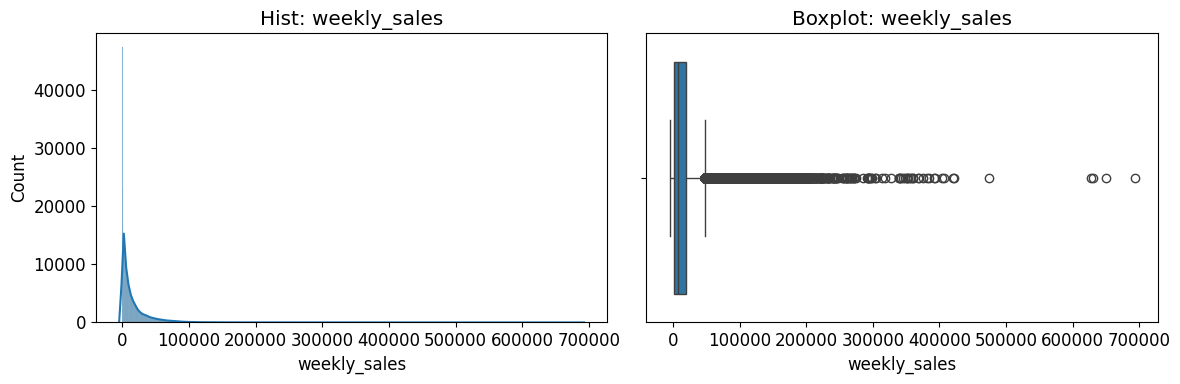

count        45.000000
mean     130287.600000
std       63825.271991
min       34875.000000
25%       70713.000000
50%      126512.000000
75%      202307.000000
max      219622.000000
Name: size, dtype: float64
Выбросы:
Количество: 0
Процент: 0.0
Границы: -126678.0 399698.0
Первые 5 выбросов выше верхней границы: []
5 максимальных значений: []
Первые 5 выбросов ниже нижней границы: []
5 минимальных значений: []


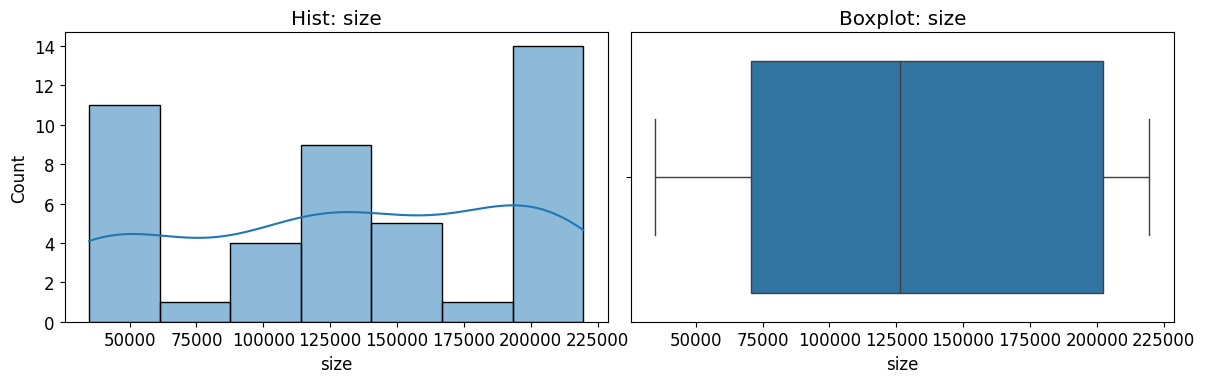

count    421570.000000
mean         60.090059
std          18.447931
min          -2.060000
25%          46.680000
50%          62.090000
75%          74.280000
max         100.140000
Name: temperature, dtype: float64
Выбросы:
Количество: 69
Процент: 0.02
Границы: 5.28 115.68
Первые 5 выбросов выше верхней границы: []
5 максимальных значений: []
Первые 5 выбросов ниже нижней границы: [-2.06 -2.06 -2.06 -2.06 -2.06]
5 минимальных значений: [-2.06 -2.06 -2.06 -2.06 -2.06]


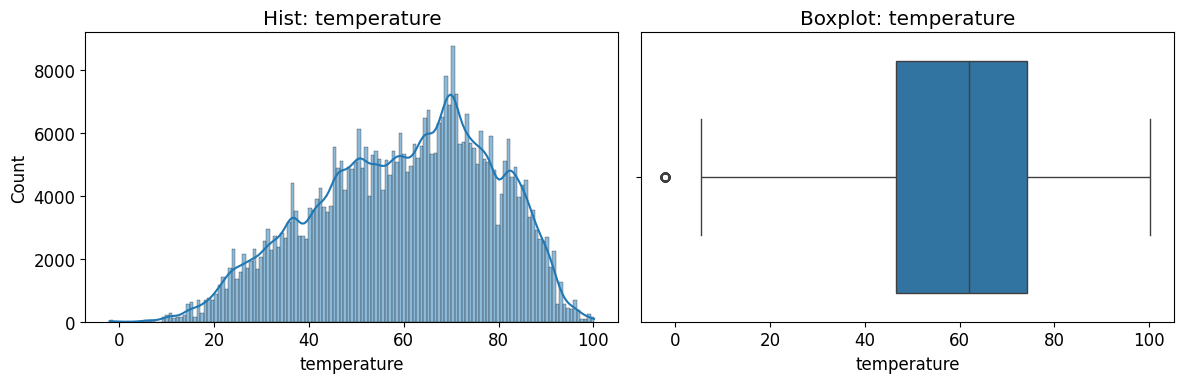

count    421570.000000
mean          3.361027
std           0.458515
min           2.472000
25%           2.933000
50%           3.452000
75%           3.738000
max           4.468000
Name: fuel_price, dtype: float64
Выбросы:
Количество: 0
Процент: 0.0
Границы: 1.73 4.95
Первые 5 выбросов выше верхней границы: []
5 максимальных значений: []
Первые 5 выбросов ниже нижней границы: []
5 минимальных значений: []


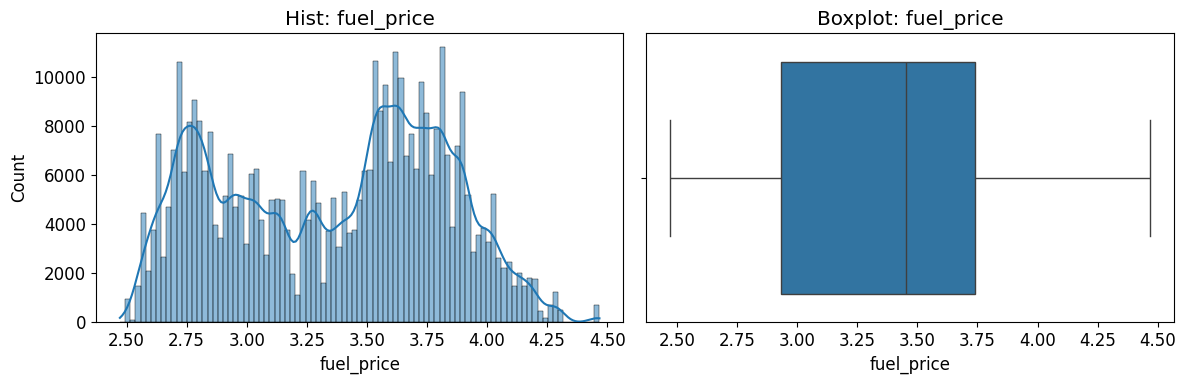

count    421570.000000
mean        171.201947
std          39.159276
min         126.064000
25%         132.022667
50%         182.318780
75%         212.416993
max         227.232807
Name: cpi, dtype: float64
Выбросы:
Количество: 0
Процент: 0.0
Границы: 11.43 333.01
Первые 5 выбросов выше верхней границы: []
5 максимальных значений: []
Первые 5 выбросов ниже нижней границы: []
5 минимальных значений: []


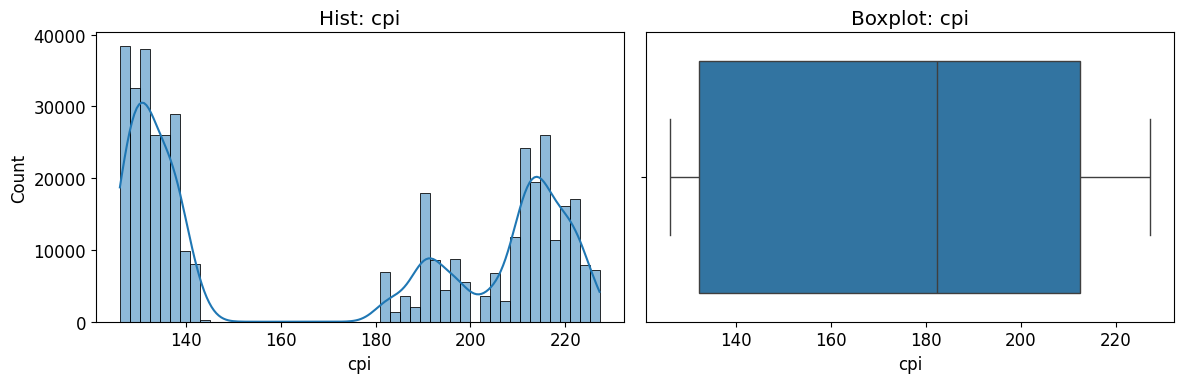

count    421570.000000
mean          7.960289
std           1.863296
min           3.879000
25%           6.891000
50%           7.866000
75%           8.572000
max          14.313000
Name: unemployment, dtype: float64
Выбросы:
Количество: 32114
Процент: 7.62
Границы: 4.37 11.09
Первые 5 выбросов выше верхней границы: [11.627 11.627 11.627 11.627 11.627]
5 максимальных значений: [14.313 14.313 14.313 14.313 14.313]
Первые 5 выбросов ниже нижней границы: [4.308 4.308 4.308 4.308 4.308]
5 минимальных значений: [3.879 3.879 3.879 3.879 3.879]


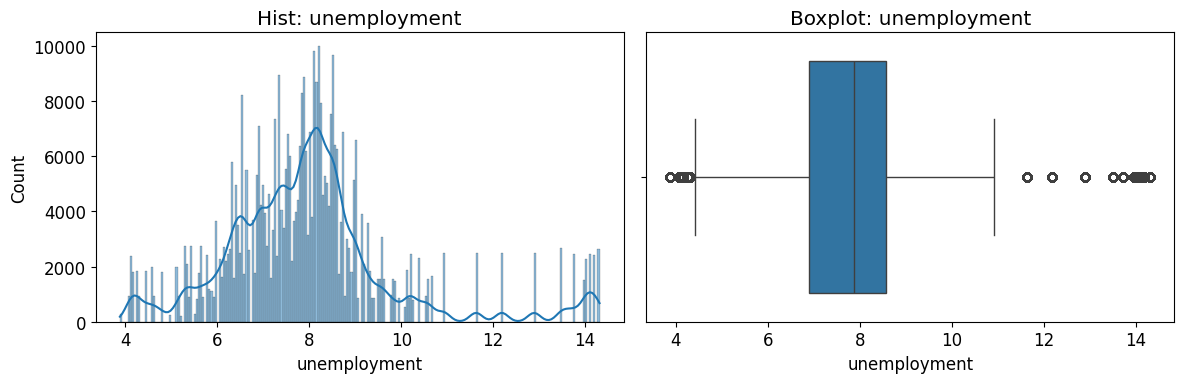

In [14]:
data_review(sales, 'weekly_sales')
data_review(stores, 'size')
data_review(features, 'temperature')
data_review(features, 'fuel_price')
data_review(features, 'cpi')
data_review(features, 'unemployment')

<h4>Выводы по анализу числовых признаков</h4>
<ul>
    <li><code>weekly_sales</code> - сильный правый хвост. IQR относит к выбросам 35521 значений, но это природа данных, а не ошибка. Минимум <b>−4988.94</b> есть отрицательные продажы т.к. основная цель прогноз закупок ставим значение 0 </li>
    <li><code>size</code> - выбросов нет, распределение с пиками 50т, 125т и 200т единиц. Три пика соответствуют типам дарксторов, есть связь <code>size</code> и <code>type</code></li>
    <li><code>temperature</code> −2.06 - 100.14, распределение нормальное. 69 выбросов это повторяющееся значение одной холодной недели, удалять его не нужно</li>
    <li><code>fuel_price</code> 2.47 - 4.47, выбросов нет. Распределение отражает изменение цен в зависимости от времени</li>
    <li><code>cpi</code> 126 - 227, выбросов нет, распределение с разрывом в 140–180. Это указывает на две группы с разным уровнем цен</li>
    <li><code>unemployment</code> 3.88 - 14.31. IQR относит к выбросам 32114 значений, но это региональные различия: в отдельных регионах безработица устойчиво выше или ниже</li>
</ul>

<h4>Решения по обработке</h4>
<ul>
    <li>Высокие значения <code>weekly_sales</code> сохраняем</li>
    <li>Отрицательные значения <code>weekly_sales</code> ставим значение 0</li>
    <li>Выбросы в факторах <code>temperature</code>, <code>unemployment</code> оставляем</li>
</ul>

In [15]:
mask = sales['weekly_sales'] < 0
print('Отрицательных значений:', mask.sum())
print('Доля:',  round(mask.mean() * 100, 2))

sales.loc[sales['weekly_sales'] < 0, 'weekly_sales'] = 0

print('Новый минимум продаж:', sales['weekly_sales'].min())

Отрицательных значений: 1285
Доля: 0.3
Новый минимум продаж: 0.0


<h2>Этап 3 Объединяем таблицы, проверяем итоговые данные</h2>

<h3>Объединение таблиц</h3>

In [16]:
key = ['store', 'dept', 'date']
df = (sales.merge(features, on=key, how='left').merge(stores, on='store', how='left'))
plan = plan.merge(stores, on='store', how='left')

<h3>Заполняем пропуски по признакам factor</h3> 

пропуски согласно заданию заполняются средним

In [17]:
factor_cols = ['factor2', 'factor3', 'factor4', 'factor5']
df['date'] = pd.to_datetime(df['date'])

means = df.loc[df['date'] < '2025-09-01', factor_cols].mean()
df[factor_cols] = df[factor_cols].fillna(means)

<h3>Создане лаговых признаков</h3>

In [ ]:
def create_temporal_features(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['year'] = df['date'].dt.year
    return df

def create_avg_sales_feature(df):
    df = df.copy().sort_values(['store', 'dept', 'date'])
    grouped = df.groupby(['store', 'dept'])['weekly_sales']
    df['avg_sales_before'] = grouped.transform(lambda x: x.shift(1).expanding().mean())
    return df

def create_lag_features(df):
    df = df.copy().sort_values(['store', 'dept', 'date'])
    grouped = df.groupby(['store', 'dept'])['weekly_sales']
    df['sales_1week_ago'] = grouped.shift(1)
    df['sales_2week_ago'] = grouped.shift(2)
    df['sales_4week_ago'] = grouped.shift(4)
    return df

def create_rolling_features(df):
    df = df.copy().sort_values(['store', 'dept', 'date'])
    grouped = df.groupby(['store', 'dept'])['weekly_sales']
    df['mean_sales_2week'] = grouped.transform(lambda x: x.shift(1).rolling(window=2, min_periods=1).mean())
    df['mean_sales_4week'] = grouped.transform(lambda x: x.shift(1).rolling(window=4, min_periods=1).mean())
    return df

df = create_temporal_features(df)
df = create_avg_sales_feature(df)
df = create_lag_features(df)
df = create_rolling_features(df)

print('Строк:', len(df), 'колонок:', df.shape[1])

new_cols = ['month', 'quarter', 'year', 'avg_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago', 'mean_sales_2week', 'mean_sales_4week']
print('Пропуски в новых признаках:')
print(df[new_cols].isna().sum())

df[new_cols].head()

Строк: 421570 колонок: 25
Пропуски в новых признаках:
month                   0
quarter                 0
year                    0
avg_sales_before     3331
sales_1week_ago      3331
sales_2week_ago      6625
sales_4week_ago     13134
mean_sales_2week     3331
mean_sales_4week     3331
dtype: int64


,month,quarter,year,avg_sales_before,sales_1week_ago,sales_2week_ago,sales_4week_ago,mean_sales_2week,mean_sales_4week
0,2,1,2023,NaN,NaN,NaN,NaN,NaN,NaN
5747,2,1,2023,24924.500000,24924.50,NaN,NaN,24924.500,24924.500000
6829,2,1,2023,35481.995000,46039.49,24924.50,NaN,35481.995,35481.995000
11698,2,1,2023,37519.846667,41595.55,46039.49,NaN,43817.520,37519.846667
12681,3,1,2023,32990.770000,19403.54,41595.55,24924.5,30499.545,32990.770000


In [19]:
df = df.reset_index(drop=True)

<h4>Создание признаков</h4>
<ul>
    <li>Созданы временные признаки <code>month</code>, <code>quarter</code>, <code>year</code></li>
    <li>Созданы лаговые признаки продаж за 1, 2, 4 недели назад, скользящие средние за 2 и 4 недели и накопительное среднее <code>avg_sales_before</code></li>
    <li>Все рассчитаны по паре <code>store</code> - <code>dept</code> со сдвигом <code>shift(1)</code></li>
    <li>Пропуски возникают только в начале каждого времянного периода, такие пропуски будут заполнены нулями</li>
</ul>

<h4>Инструменты для лаговых признаков</h4>
<ul>
    <li><code>shift(n)</code> сдвигает ряд на <code>n</code> строк вниз</li>
    <li><code>rolling(n)</code> - скользящее окно длины n(для каждой строки берутся <code>w</code> последних значений</li>
    <li><code>expanding()</code> - расширяющееся окно: для каждой строки берутся все значения от на. С <code>.mean()</code> даёт накопительное среднее продаж за всю историю отдела — признак <code>avg_sales_before</code></li>
    <li>Все операции выполняются внутри <code>groupby(['store', 'dept'])</code>, чтобы окно не выходило за пределы одного ряда «даркстор — отдел»</li>
</ul>

<h3>Анализ взаимосвязей в итоговой таблице</h3>

<h4>Динамика по неделям</h4>

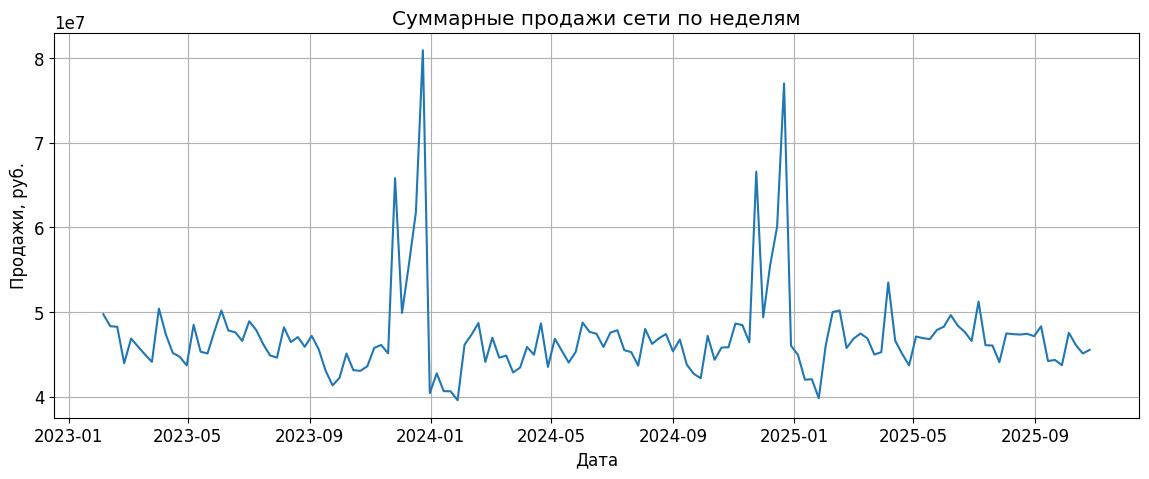

In [20]:
weekly = df.groupby('date')['weekly_sales'].sum()

plt.figure(figsize=(14, 5))
plt.plot(weekly)
plt.title('Суммарные продажи сети по неделям')
plt.xlabel('Дата')
plt.ylabel('Продажи, руб.')
plt.grid()
plt.show()

Видны четкие пики в ноябре и декабре следует проверить на сколько процентов продажи превышают норму 

In [21]:
weekly = df.groupby('date')['weekly_sales'].sum()
mean_week = weekly.mean()
nov_dec = weekly[weekly.index.month.isin([11, 12])]
print('Средняя неделя:', round(mean_week))
print()
for date, sales in nov_dec.items():
    print(date.date(), round(sales), f'{sales / mean_week * 100 - 100:+.0f}%')

Средняя неделя: 47114036

2023-11-05 45782284 -3%
2023-11-12 46124901 -2%
2023-11-19 45126774 -4%
2023-11-26 65821216 +40%
2023-12-03 49910640 +6%
2023-12-10 55667840 +18%
2023-12-17 61821318 +31%
2023-12-24 80931586 +72%
2023-12-31 40434740 -14%
2024-11-03 48655868 +3%
2024-11-10 48474278 +3%
2024-11-17 46439392 -1%
2024-11-24 66593836 +41%
2024-12-01 49390610 +5%
2024-12-08 55561558 +18%
2024-12-15 60086723 +28%
2024-12-22 76999774 +63%
2024-12-29 46044301 -2%


<h4>Выводы по недельной динамике</h4>
<ul>
    <li>Базовый уровень продаж сети стабилен</li>
    <li>Внутри года колебания небольшие без разницы между весной, летом и осенью</li>
    <li>Вся сезонность сосредоточена в конце года и повторяется ежегодно:
        <ul>
            <li>последняя неделя ноября +40%, соседние недели на обычном уровне</li>
            <li>декабрь ступенчатый рост с пиком в последнюю неделю перед Новым годом (+63–72%)</li>
            <li>новогодняя неделя и январь провал ниже среднего</li>
        </ul>
    </li>
    <li>Для модели полезно знать положение недели относительно Нового года, а не месяц</li>
</ul>

In [22]:
df['day_of_year'] = df['date'].dt.dayofyear
df['weeks_to_new_year'] = (365 - df['day_of_year']) // 7

<h4>Распределение целевой переменной по признакам</h4>

In [23]:
def target_distribution(df, x, by, top=None):
    value_mean = df.groupby(by)[x].mean().sort_values(ascending=False)
    if top:
        value_mean = value_mean.head(top)
    print(f'Среднее {x} по {by}:')
    print(value_mean)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=value_mean.index.astype(str), y=value_mean.values, color='blue')
    plt.title(f'Распределение {x} по {by}')
    plt.xlabel(by)
    plt.ylabel(f'Среднее {x}')
    plt.show()

Среднее weekly_sales по month:
month
12    19356.052933
11    17491.151001
6     16319.619933
8     16062.717520
2     16008.947611
7     15832.959284
5     15776.455683
4     15721.475799
3     15367.789482
10    15244.132643
9     15096.249922
1     14126.220965
Name: weekly_sales, dtype: float64


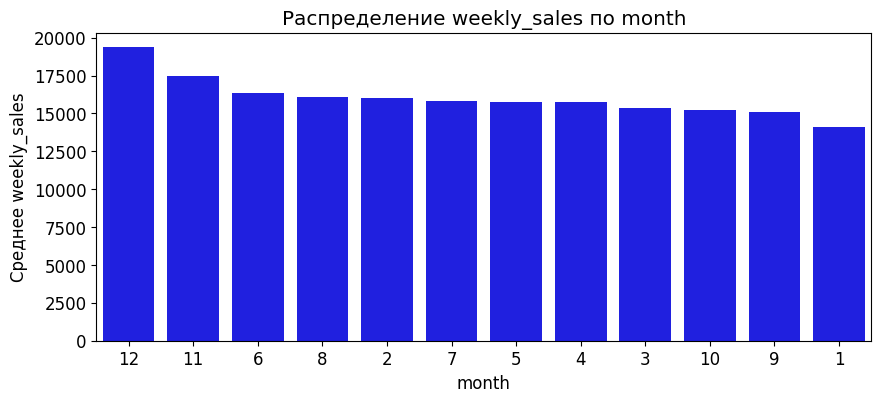

Среднее weekly_sales по is_holiday:
is_holiday
True     17036.092349
False    15901.649652
Name: weekly_sales, dtype: float64


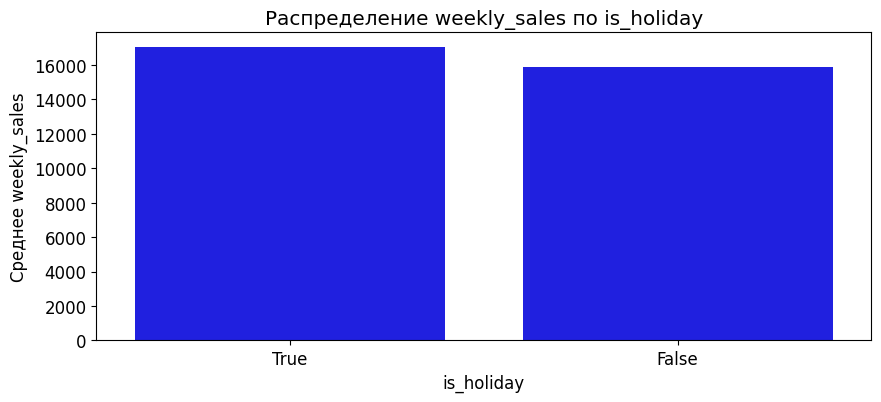

Среднее weekly_sales по type:
type
A    20099.766466
B    12237.326208
C     9519.638045
Name: weekly_sales, dtype: float64


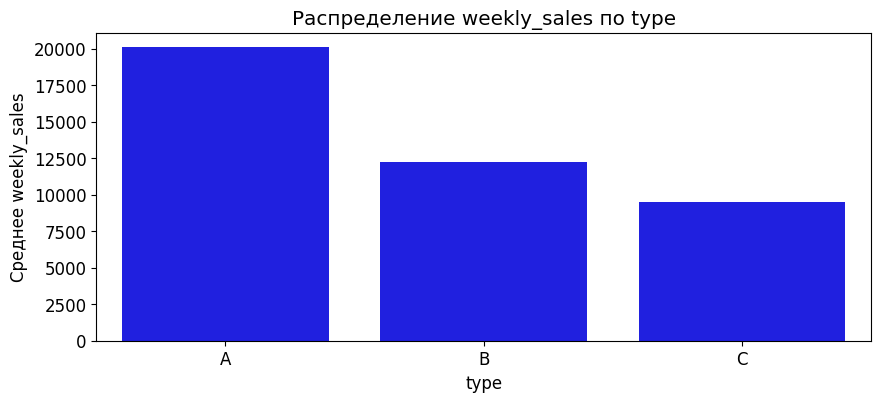

Среднее weekly_sales по store:
store
20    29508.652971
4     29161.338522
14    28785.046259
13    27355.160432
2     26898.530524
10    26332.923838
27    24827.109044
6     21913.484315
1     21710.929985
39    21000.859914
19    20362.405184
23    19776.392577
31    19682.008515
11    19276.922281
24    18969.162750
Name: weekly_sales, dtype: float64


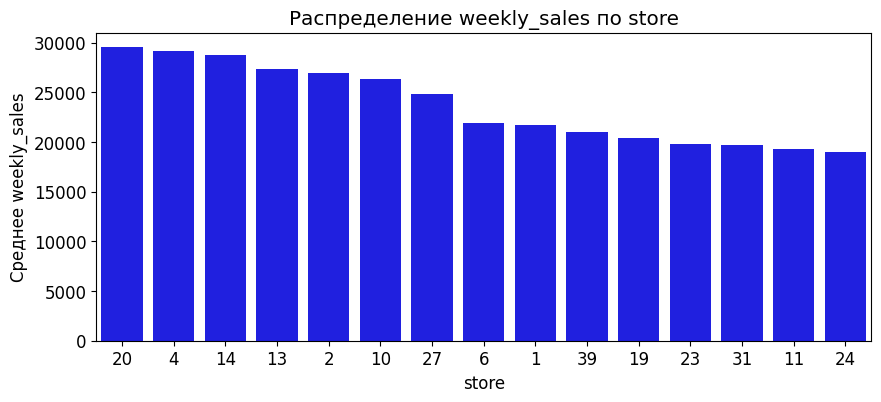

Среднее weekly_sales по dept:
dept
92    75204.870531
95    69824.423080
38    61090.619568
72    50567.019482
65    45441.706224
90    45232.084488
40    44900.702727
2     43607.020113
91    33687.910758
94    33405.997909
13    30663.802634
8     30191.263517
93    27008.063902
4     25974.630238
7     24161.237413
23    23931.479645
79    21973.044932
5     21365.583521
9     20206.714964
46    19944.741483
Name: weekly_sales, dtype: float64


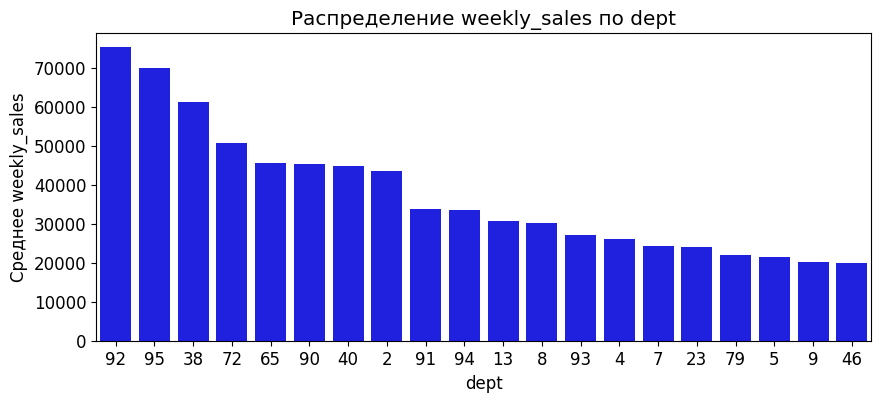

In [24]:
target_distribution(df, 'weekly_sales', 'month')
target_distribution(df, 'weekly_sales', 'is_holiday')
target_distribution(df, 'weekly_sales', 'type')
target_distribution(df, 'weekly_sales', 'store', top=15)
target_distribution(df, 'weekly_sales', 'dept', top=20)

<h4>Выводы по распределению целевой переменной по признакам</h4>
<ul>
    <li><b>Месяц.</b> Декабрь самый высокий по продажам (19356 руб.), ноябрь второй (17491), январь самый слабый (14126)</li>
    <li><b>Праздники.</b> В праздничные недели продажи выше только на 7%. Пики приходятся на предпраздничные недели, а не на праздники</li>
    <li><b>Тип даркстора.</b> A - 20100, B - 12237, C - 9520</li>
    <li><b>Отдел.</b> Самый сильный разброс: отделы 92, 95 и 38 продают на 61000–75000  в неделю, в то время как большинство около 20000. Уровень продаж определяется отделом</li>
</ul>

<h3>Корреляции</h3>

In [25]:
def phik_corr_matrix(df, interval_cols=None, drop_cols=None):
    data = df.copy()
    
    if drop_cols:
        data = data.drop(columns=drop_cols, errors='ignore')

    plt.figure(figsize = (14, 12))
    corr = data.phik_matrix(interval_cols=interval_cols)
    sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')
    plt.show()
    
    return corr

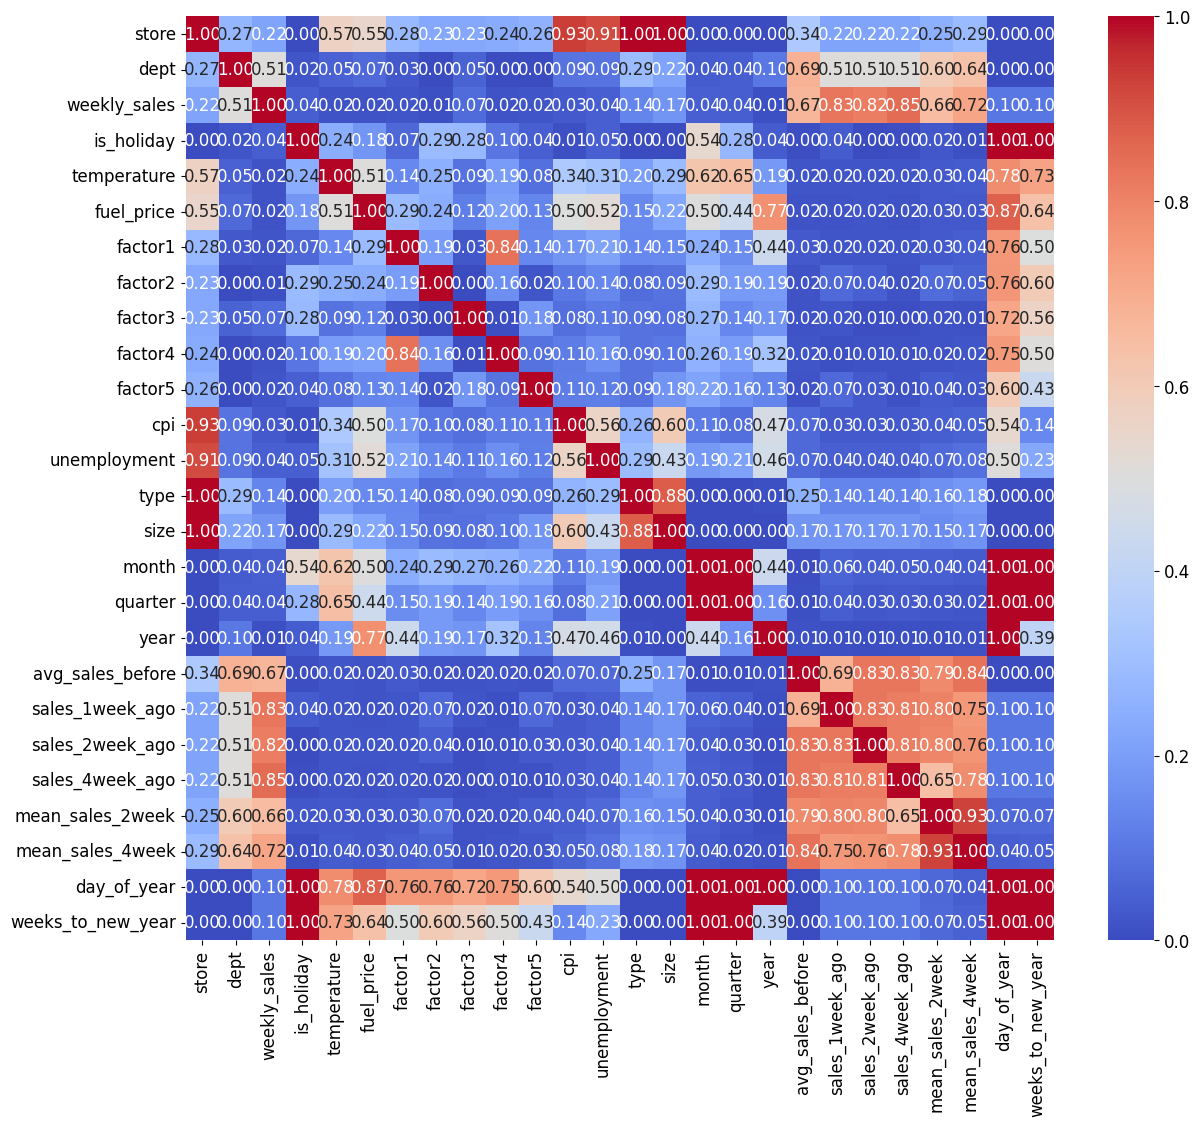

In [26]:
interval_cols = ['weekly_sales', 'size', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'factor1', 'factor2', 'factor3', 'factor4', 'factor5',
                 'avg_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago', 'mean_sales_2week', 'mean_sales_4week',]
drop_cols = ['date']

corr = phik_corr_matrix(df, interval_cols=interval_cols, drop_cols=drop_cols)

<h4>Выводы по корреляционному анализу</h4>
<ul>
    <li>Связь с целевой переменной. Сильнее всего с <code>weekly_sales</code> связаны лаговые признаки: скользящее среднее за 4 недели, лаги за 1, 2 и 4 недели и накопительное среднее <code>avg_sales_before</code></li>
    <li>Признак <code>weeks_to_new_year</code> показывает слабую связь с целевой. Это не опровергает выявленную ранее зависимость: пик затрагивает только несколько недель в году, и на всей выборке его вклад уменьшается</li>
    <li>Мультиколлинеарность связанные признаков - характеристики даркстора: <code>store</code> определяет <code>type</code> и <code>size</code>, а <code>type</code> связан с <code>size</code></li>
    <li>Временные признаки <code>month</code>, <code>quarter</code>, <code>year</code>, <code>weeks_to_new_year</code> и <code>is_holiday</code> коррелируют между собой, поскольку все получаются из даты</li>
    <li>Внешние факторы связаны с календарём температура и акционный товар отражают текущий сезон</li>
</ul>

<h2>Этап 4 Отсортируем данные по вреемени выдели обучающую выборку до августа 2025 г. Проведём мониторинг стабильности признаков используя PSI</h2>

<h3>Разобъём данные на выборки</h3>

Удалим строки с пропусками

In [27]:
rows_before = len(df)
df = df.dropna().reset_index(drop=True)
print('Удалено строк:', rows_before - len(df))

Удалено строк: 13134


отделяем train и val выборки

In [28]:
cat_features = ['store', 'dept', 'type']
df[cat_features] = df[cat_features].astype("category")

df = df.sort_values('date').reset_index(drop=True)
train = df[df['date'] < '2025-09-01']
val = df[(df['date'] >= '2025-09-01') & (df['date'] <= '2025-10-31')]

print('Train:', train['date'].min().date(), '-', train['date'].max().date(), 'Объём', len(train))
print('Valid:', val['date'].min().date(), '-', val['date'].max().date(), 'Объём', len(val))

Train: 2023-03-05 - 2025-08-31 Объём 384726
Valid: 2025-09-07 - 2025-10-26 Объём 23710


<h3>Расчитываем PSI</h3>

In [29]:
def calculate_psi(expected, actual, buckets=10, epsilon=1e-10):
    expected = expected.dropna()
    actual = actual.dropna()

    breaks = np.linspace(min(np.nanmin(expected), np.nanmin(actual)),
                         max(np.nanmax(expected), np.nanmax(actual)), buckets + 1)

    expected_bins = np.histogram(expected, bins=breaks)[0] / len(expected)
    actual_bins = np.histogram(actual, bins=breaks)[0] / len(actual)

    expected_bins = np.where(expected_bins == 0, epsilon, expected_bins)
    actual_bins = np.where(actual_bins == 0, epsilon, actual_bins)

    psi = sum((actual_bins[i] - expected_bins[i]) * np.log(actual_bins[i] / expected_bins[i])
              for i in range(buckets))
    return psi

In [30]:
psi_cols = ['size', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'factor1', 'factor2', 'factor3', 'factor4', 'factor5',
            'month', 'quarter', 'year', 'weeks_to_new_year', 'avg_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_4week_ago',
            'mean_sales_2week', 'mean_sales_4week',]

psi_values = {}
for col in psi_cols:
    psi_values[col] = calculate_psi(train[col], val[col])

psi_df = pd.DataFrame({'PSI': psi_values}).sort_values('PSI', ascending=False)
psi_df.round(3)

,PSI
month,19.661
year,17.052
weeks_to_new_year,16.756
quarter,11.832
fuel_price,11.795
temperature,3.122
unemployment,1.455
cpi,1.044
factor2,0.450
factor1,0.331


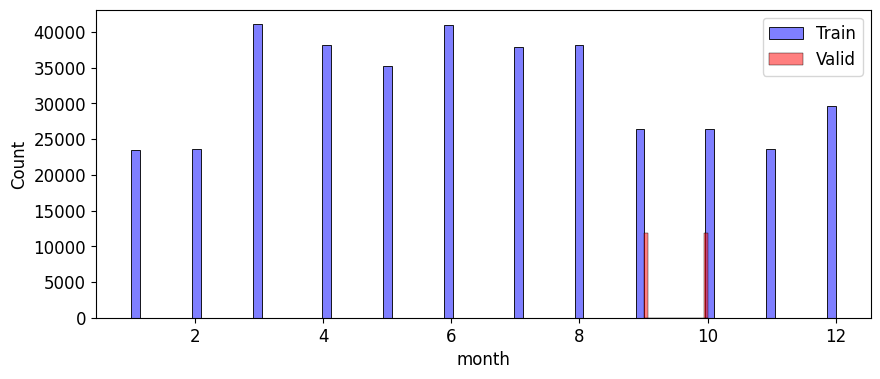

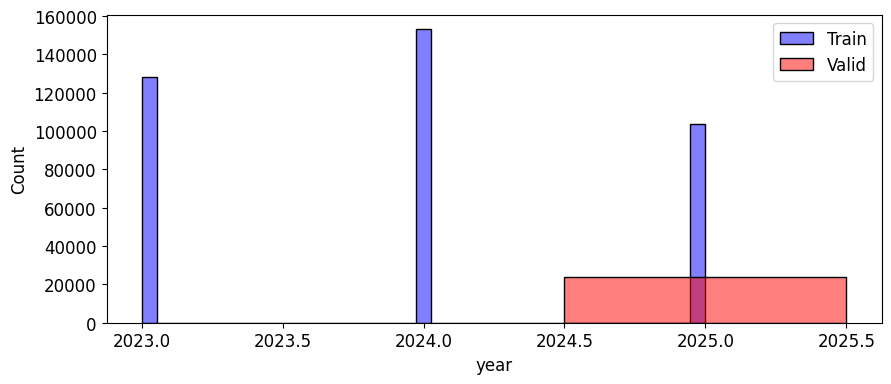

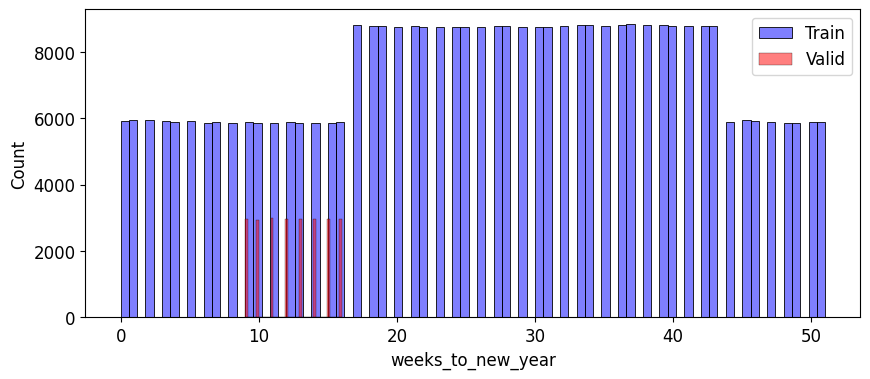

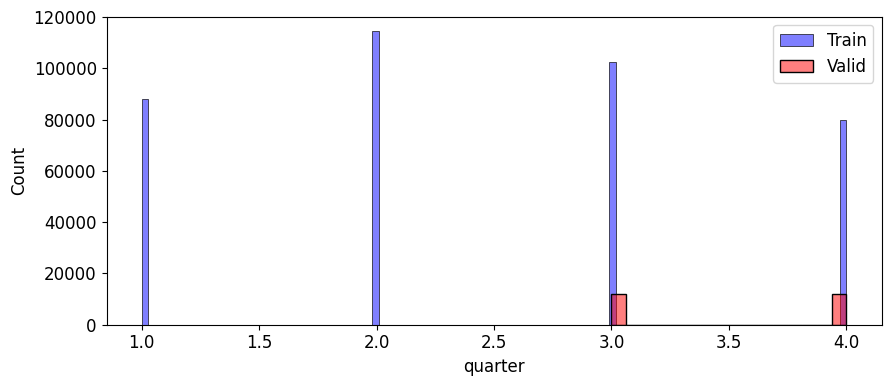

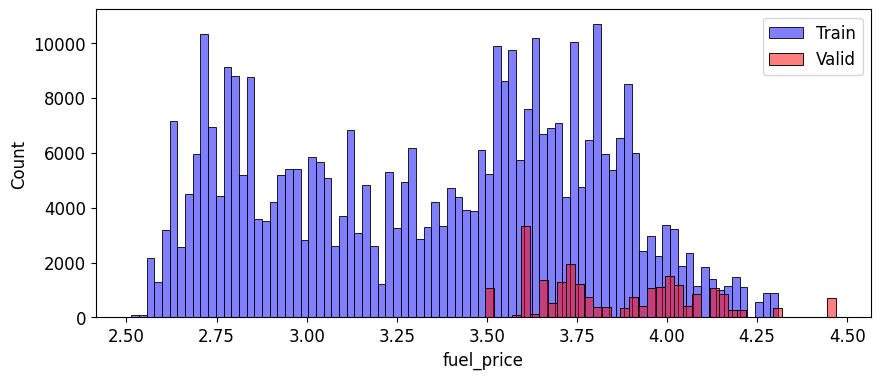

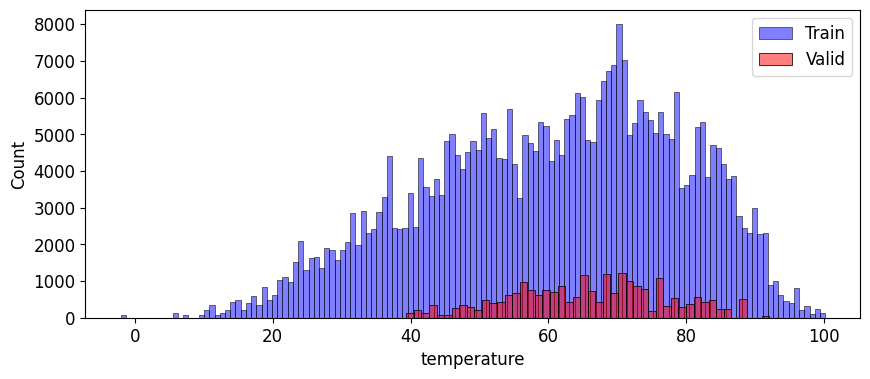

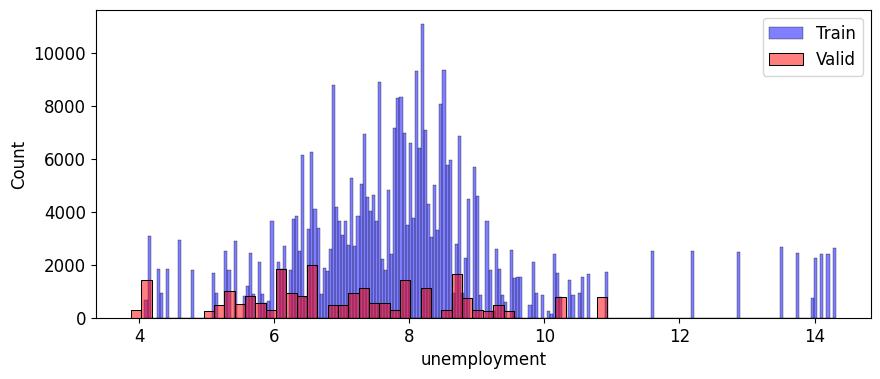

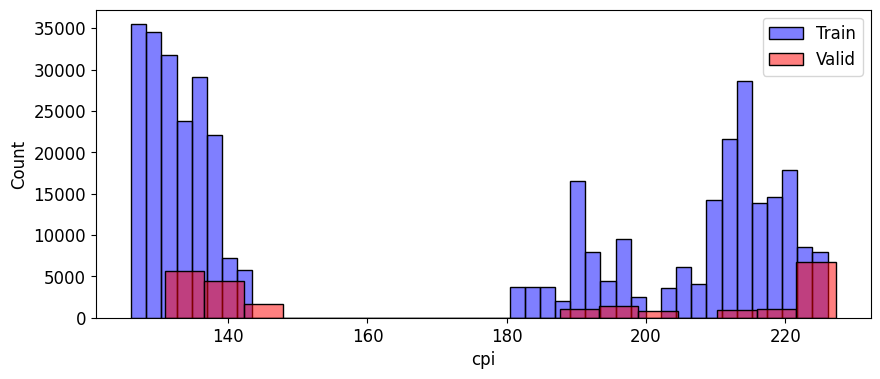

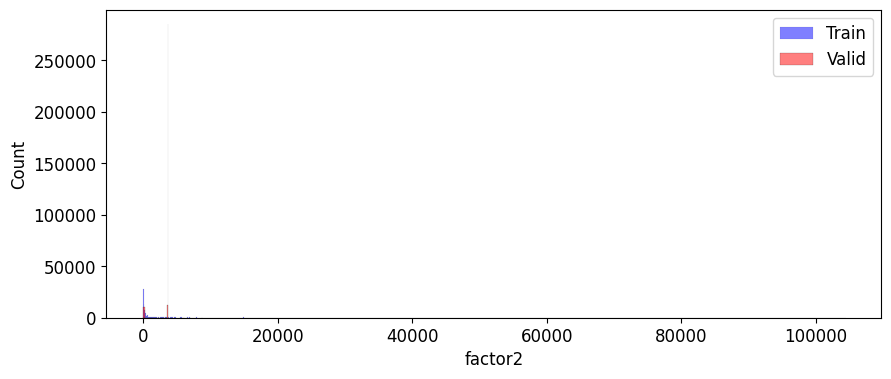

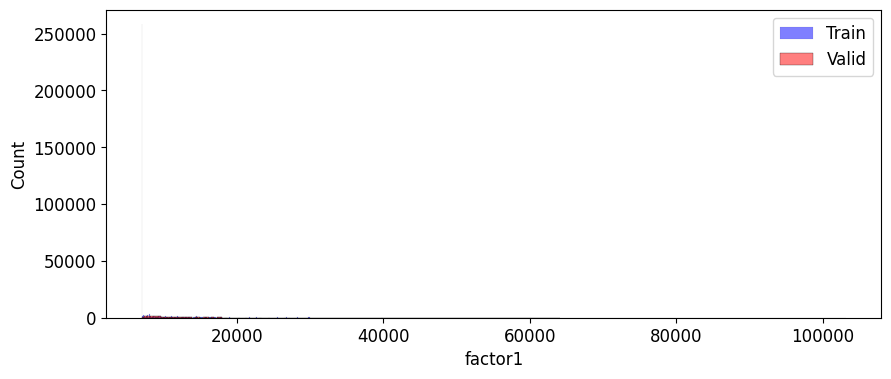

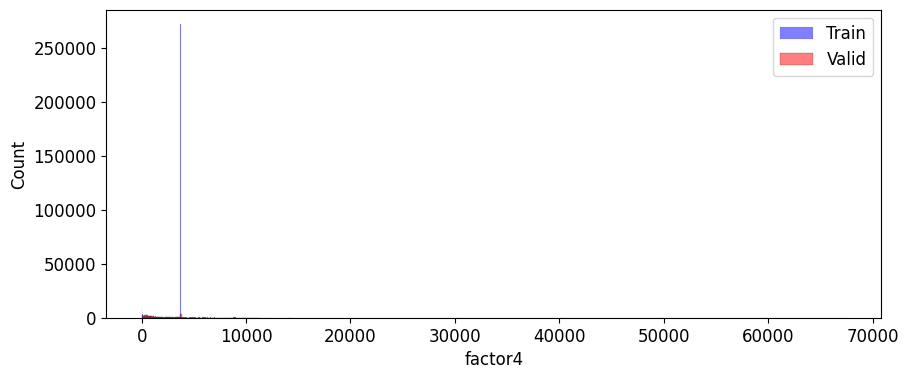

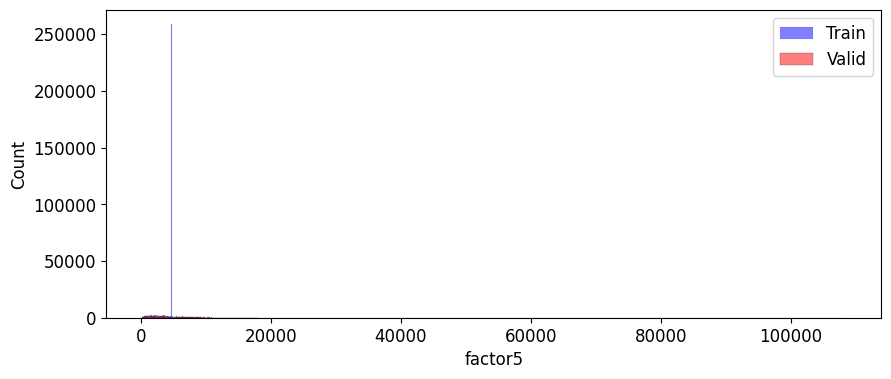

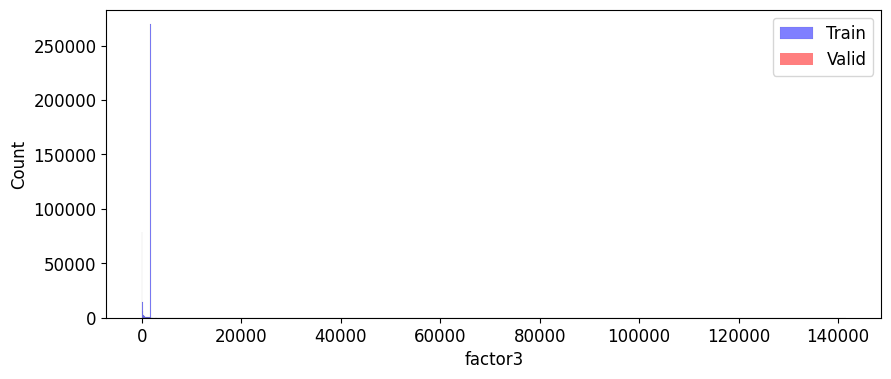

In [32]:
drift_cols = psi_df[psi_df['PSI'] >= 0.1].index

for col in drift_cols:
    plt.figure(figsize=(10, 4))
    sns.histplot(train[col], color='blue', alpha=0.5, label='Train')
    sns.histplot(val[col], color='red', alpha=0.5, label='Valid')
    plt.xlabel(col)
    plt.legend()
    plt.show()

<h4>Выводы по мониторингу стабильности признаков</h4>
<ul>
    <li>Стабильные признаки: лаги продаж, скользящие средние, <code>avg_sales_before</code> и <code>size</code></li>
    <li>Календарные признаки <code>month</code>, <code>quarter</code>, <code>weeks_to_new_year</code> PSI от 11.8 до 19.7. Это результат разбиения по времени, так как валидация содержит только сентябрь и октябрь 2025 года</li>
    <li><code>year</code> исключается: прогноз включает 2026 год, которого нет в обучении</li>
    <li>Внешние факторы <code>fuel_price</code>, <code>temperature</code>, <code>unemployment</code>, <code>cpi</code> реальный сильный дрейф + слабая связь с целевой переменной - признаки исключаются</li>
    <li>Промоакции <code>factor1</code> - <code>factor5</code> у 3 из 5 PSI выше 0.2, у оставшихся умеренный дрейф. После заполнения пропусков средним большая часть значений сосредоточена в одной точке, связь с целевой переменной слабая - признаки исключаются</li>
</ul>

In [33]:
drop_cols = ['year', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'factor1', 'factor2', 'factor3', 'factor4', 'factor5']

train = train.drop(columns=drop_cols)
val = val.drop(columns=drop_cols)

<h2>Этап 5 Обучение модели: Обучим модель CatBoostRegressor проанализируем метрики</h2>

In [34]:
target = 'weekly_sales'
drop_cols = ['date', target]
cat_features = ['store', 'dept', 'type']

X_train = train.drop(columns=drop_cols)
y_train = train[target]
X_val = val.drop(columns=drop_cols)
y_val = val[target]


cb = CatBoostRegressor(depth=6, cat_features=cat_features, random_seed=RANDOM_STATE, early_stopping_rounds=100, verbose=0)

start = time.time()
cb.fit(X_train, y_train, eval_set=(X_val, y_val))
print("Время обучения:", time.time() - start)

Время обучения: 110.16941499710083


In [35]:
def get_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
            'R2': r2_score(y_true, y_pred),}

pred_train = cb.predict(X_train).clip(min=0)
pred_val = cb.predict(X_val).clip(min=0)

metrics = pd.DataFrame({'Train': get_metrics(y_train, pred_train),
                        'Val': get_metrics(y_val, pred_val),}).round(3)
display(metrics)

,Train,Val
MAE,1417.426,1316.433
RMSE,2938.016,2788.698
R2,0.983,0.984


<h4>Выводы по качеству модели</h4>
<ul>
    <li>На валидации MAE 1316 руб., RMSE 2789 руб., R² 0.984. Ошибка около 8% с учетом средних продаж 16000</li>
    <li>Переобучения нет: метрики на train и val почти совпали</li>
    <li>На валидации метрики слегка лучше, так как она идет без предпраздничных пиков</li>
</ul>


<h2>Этап 6 Анализ важности признаков: Оценим важность признаков с помощью подходящего инструмента для оценки важности</h2>

In [36]:
def create_SHAP(model, df, model_name):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(df)

    plt.figure(figsize=(6, 4))
    shap.summary_plot(shap_values, df, show=False)
    plt.title(f"SHAP Summary Plot: {model_name}")
    plt.tight_layout()
    plt.show()

    return shap_values

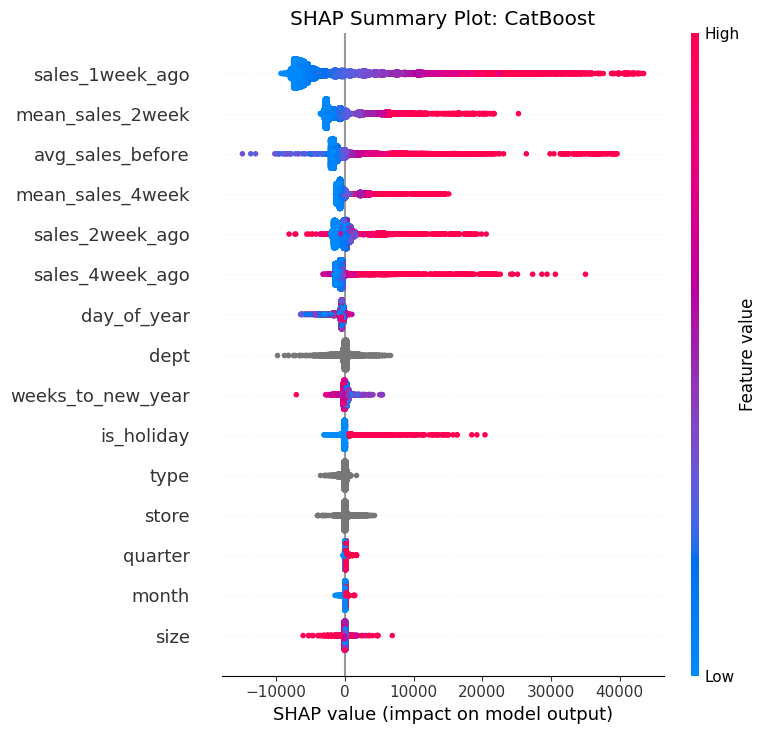

In [37]:
shap_values = create_SHAP(cb, X_val, "CatBoost")

<h4>Выводы по важности признаков</h4>
<ul>
    <li>Основной вклад вносят истории продаж: <code>sales_1week_ago</code> и <code>avg_sales_before</code></li>
    <li><code>dept</code> и <code>store</code> так же важны - они задают уровень продаж отдела</li>
    <li><code>is_holiday</code> и<code>weeks_to_new_year</code> увеличивают проноз, это подтверждает сезонность</li>
</ul>

<h2>Этап 7 Отчет: сделаем финальный вывод о проделанной работе и сохраним артефакты в S3</h2>

In [38]:
import io
import pickle
import boto3

load_dotenv('project.env')

s3_client = boto3.client(
    's3',
    endpoint_url='https://storage.yandexcloud.net',
    aws_access_key_id=os.getenv('S3_ACCESS_KEY_ID'),
    aws_secret_access_key=os.getenv('S3_SECRET_KEY'),
    region_name='ru-central1',
)

filebuffer = io.BytesIO()
pickle.dump(cb, filebuffer)
filebuffer.seek(0)

s3_client.upload_fileobj(
    Fileobj=filebuffer,
    Bucket=os.getenv('S3_BUCKET'),
    Key='catboost_model.pkl',
)

print(f"Модель успешно загружена в {os.getenv('S3_BUCKET')}/catboost_model.pkl")

Модель успешно загружена в s3-ds-20260826-8e90283717/catboost_model.pkl


<h2>Итоговый вывод</h2>
<ul>
    <li>Задача Построена модель прогнозирования недельных продаж для каждой пары даркстор - отдел сети Прилавок на данных за февраль 2023 - октябрь 2025 года</li>
    <li>Дубликатов нет. Отрицательные продажи приведены к нулю, так как объём закупки не может быть отрицательным. Пропуски в признаках промоакций заполнены средним по обучающему периоду</li>
    <li>EDA уровень продаж стабилен, сезонность в конце года: всплеск в последнюю неделю ноября и понедельный рост в декабре с пиком перед Новым годом, в конце провал в январе</li>
    <li>Созданы календарные признаки, число недель до Нового года, лаги, скользящие средние и накопительное среднее продаж. Все признаки рассчитаны со сдвигом на неделю</li>
    <li>Внешние факторы, промоакции исключены у них превышенный дрейф данных</li>
    <li>CatBoostRegressor на 14 признаках: MAE - 1316 руб., RMSE - 2789 руб., R² - 0.984 на валидации, переобучения нет</li>
    <li>Модель сохранена в S3 следующий этап - Airflow DAG, который еженедельно формирует прогноз на период ноябрь 2025 - июль 2026</li>
</ul>